# RBI Weekly Dataset — Exploratory Data Analysis

**Dataset:** `tapatir630_17866381335214086.csv` (675 rows × 26 columns)

**Workflow followed:** *Exploratory Data Analysis — A Standard 23-Step Checklist for Any Dataset*

In [1]:
# Core imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 50)

RAW_PATH = "/kaggle/input/datasets/tapatiroy2718/rbi-foreign-exchange-reserves/tapatir630_17866381335214086.csv"
df = pd.read_csv(RAW_PATH)

df.head()


,Country,Year,Month,Date,"M3 (UOM:INR(IndianRupees)), Scaling Factor:10000000","M3 Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Currency With The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000","Demand Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000","Time Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000","Time Deposits With Banks Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Other Deposits With Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Bank Credit To Government (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Bank Credit To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Bank Credit To Government Including Merger From Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Credit Of Other Banks To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Bank Credit Of Other Banks Including Merger To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial Sector (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial Sector Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial Sector From Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial By Other Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial By Other Banks Includimg Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Foreign Exchange Assets Of Banking Sector (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Governments Currency Liabilities To The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Banking Sectors Net Non Monetary Liabilities (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Banking Sectors Net Non Monetary Liabilities Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Non Monetary Liabilities Of Reserve Bank Of India (Rbi) Under Banking Sectors Net Non-Monetary Liabilities (UOM:INR(IndianRupees)), Scaling Factor:10000000"
0,India,"Calendar Year (Jan - Dec), 2025","December, 2025",15-Dec-2025,29058340.08,NaN,3820475.628,3065540.756,22057741.58,NaN,114582.1194,8814395.101,NaN,1612903.32,7201491.781,NaN,2.050663e+07,NaN,11439.46,2.049519e+07,NaN,6.688751e+06,39720.68856,6991160.289,NaN,2810781.398
1,India,"Calendar Year (Jan - Dec), 2025","December, 2025",31-Dec-2025,29800906.25,NaN,3828358.658,3423133.329,22434415.68,NaN,114998.5832,8750685.510,NaN,1545560.88,7205124.630,NaN,2.114652e+07,NaN,20321.65,2.112620e+07,NaN,6.585472e+06,39895.31275,6721664.202,NaN,2769494.753
2,India,"Calendar Year (Jan - Dec), 2025","November, 2025",14-Nov-2025,28945871.48,NaN,3751590.760,3137173.117,21943512.16,NaN,113595.4427,8787412.250,NaN,1633175.11,7154237.140,NaN,2.017738e+07,NaN,10229.82,2.016715e+07,NaN,6.555004e+06,39231.15687,6613159.112,NaN,2605985.052
3,India,"Calendar Year (Jan - Dec), 2025","November, 2025",28-Nov-2025,29136713.20,NaN,3772033.157,3158232.507,22088553.71,NaN,117893.8227,8849634.832,NaN,1644157.44,7205477.392,NaN,2.033842e+07,NaN,11701.20,2.032672e+07,NaN,6.544991e+06,39554.51324,6635885.547,NaN,2654751.732
4,India,"Calendar Year (Jan - Dec), 2025","October, 2025",03-Oct-2025,28895269.38,NaN,3698492.216,3216574.947,21866349.52,NaN,113852.6950,8734166.548,NaN,1538513.99,7195652.558,NaN,2.006822e+07,NaN,12613.21,2.005561e+07,NaN,6.622726e+06,38863.50731,6568708.350,NaN,2569200.308


## Phase 1 — Inspect the Raw Data (Steps 1–8)

Understand the shape, structure, and quality of the raw data.

### Step 1 — Total Number of Rows
Check the row count to understand the dataset's size (`df.shape[0]`).

In [2]:
n_rows = df.shape[0]
print(f"Total rows: {n_rows}")


Total rows: 675


### Step 2 — Total Number of Columns
Check the number of variables available in the dataset (`df.shape[1]`).

In [3]:
n_cols = df.shape[1]
print(f"Total columns: {n_cols}")


Total columns: 26


### Step 3 — Understanding of Each Column

Go through every column and note what it represents, its expected values, and its role in the analysis.

| Column group | Represents | Expected values / role |
|---|---|---|
| `Country` | Country associated with the observation | India |
| `Year` | Calendar-year label | Text label such as Calendar Year (Jan - Dec), 2025 |
| `Month` | Month-period label | Text label such as December, 2025 |
| `Date` | Observation date | Date value |
| M3 / deposits / currency | Monetary aggregates | Numeric RBI values |
| Government credit variables | Net bank credit to government | Numeric RBI values |
| Commercial-sector credit variables | Bank credit to commercial sector | Numeric RBI values |
| Foreign-exchange assets | Banking-sector net foreign exchange assets | Numeric RBI values |
| Non-monetary liabilities | Banking-sector / RBI liabilities | Numeric RBI values |
| `Including Merger` variables | Series reported including merger adjustments | Numeric; some fields may be unavailable for certain periods |

**Note:** The dataset is a financial/economic time series, so missing values and extreme observations must be handled without automatically deleting potentially meaningful economic observations.


In [4]:
info_df = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "missing": df.isna().sum(),
    "sample_value": [df[c].dropna().iloc[0] if df[c].notna().any() else np.nan for c in df.columns]
})
info_df


,dtype,n_unique,missing,sample_value
Country,object,1,0,India
Year,object,25,0,"Calendar Year (Jan - Dec), 2025"
Month,object,300,0,"December, 2025"
Date,object,675,0,15-Dec-2025
"M3 (UOM:INR(IndianRupees)), Scaling Factor:10000000",float64,675,0,29058340.08
"M3 Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000",float64,54,621,27842794.0
"Currency With The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000",float64,675,0,3820475.628
"Demand Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000",float64,669,0,3065540.756
"Time Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000",float64,669,0,22057741.58
"Time Deposits With Banks Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000",float64,52,621,20987083.24


### Step 4 — Trim Extra Spaces

Strip leading/trailing whitespace from string columns and column headers. Hidden spaces can silently affect filtering, grouping, and joins.

The actual fix is performed formally during Step 16.


In [5]:
print("Header whitespace issues:")
print([c for c in df.columns if c != c.strip()])

obj_cols = df.select_dtypes(include="object").columns
whitespace_flagged = {}

for col in obj_cols:
    s = df[col].dropna().astype(str)
    whitespace_flagged[col] = int((s.str.strip() != s).sum())

print("\nColumns with leading/trailing whitespace:")
print({k: v for k, v in whitespace_flagged.items() if v > 0} or
      "No leading/trailing whitespace found.")


Header whitespace issues:
[]

Columns with leading/trailing whitespace:
No leading/trailing whitespace found.


### Step 5 — Remove Duplicate Elements
Identify fully duplicated rows and duplicate observation dates. Duplicate rows are removed; duplicate dates are inspected because a date can legitimately occur more than once only if the source structure supports it.

In [6]:
n_dupes_full = df.duplicated().sum()
print(f"Fully duplicated rows: {n_dupes_full}")

if "Date" in df.columns:
    n_dupes_date = df["Date"].duplicated().sum()
    print(f"Duplicated Date values: {n_dupes_date}")

print("\nDuplicate rows:")
display(df[df.duplicated(keep=False)].head(10))


Fully duplicated rows: 0
Duplicated Date values: 0

Duplicate rows:


,Country,Year,Month,Date,"M3 (UOM:INR(IndianRupees)), Scaling Factor:10000000","M3 Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Currency With The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000","Demand Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000","Time Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000","Time Deposits With Banks Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Other Deposits With Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Bank Credit To Government (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Bank Credit To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Bank Credit To Government Including Merger From Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Credit Of Other Banks To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Bank Credit Of Other Banks Including Merger To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial Sector (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial Sector Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial Sector From Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial By Other Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial By Other Banks Includimg Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Foreign Exchange Assets Of Banking Sector (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Governments Currency Liabilities To The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Banking Sectors Net Non Monetary Liabilities (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Banking Sectors Net Non Monetary Liabilities Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Non Monetary Liabilities Of Reserve Bank Of India (Rbi) Under Banking Sectors Net Non-Monetary Liabilities (UOM:INR(IndianRupees)), Scaling Factor:10000000"


### Step 6 — Check Memory Size
Check memory usage using `df.memory_usage(deep=True)` to understand the dataset footprint.

In [7]:
mem = df.memory_usage(deep=True)
print(mem)
print(f"\nTotal memory: {mem.sum() / 1024**2:.2f} MB")


Index                                                                                                                                                                            132
Country                                                                                                                                                                        36450
Year                                                                                                                                                                           54000
Month                                                                                                                                                                          41248
Date                                                                                                                                                                           40500
M3 (UOM:INR(IndianRupees)), Scaling Factor:10000000                                            

### Step 7 — Check Data Type of Columns
Verify that dates are datetime-compatible, monetary variables are numeric, and categorical labels remain text.

In [8]:
print(df.dtypes)

print("\nDate dtype before cleaning:", df["Date"].dtype)

numeric_candidates = [
    c for c in df.columns
    if c not in ["Country", "Year", "Month", "Date"]
]

print("\nNumber of numeric candidate columns:", len(numeric_candidates))


Country                                                                                                                                                                         object
Year                                                                                                                                                                            object
Month                                                                                                                                                                           object
Date                                                                                                                                                                            object
M3 (UOM:INR(IndianRupees)), Scaling Factor:10000000                                                                                                                            float64
M3 Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000                 

### Step 8 — Check Total Number of Null Values
Count missing values per column to establish the cleaning strategy.

In [9]:
null_counts = df.isnull().sum().sort_values(ascending=False)
null_pct = (null_counts / len(df) * 100).round(2)

null_report = pd.DataFrame({
    "nulls": null_counts,
    "pct_missing": null_pct
})

display(null_report.loc[null_counts > 0])


,nulls,pct_missing
"Time Deposits With Banks Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000",621,92.0
"M3 Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000",621,92.0
"Sources Of Bank Credit To Commercial By Other Banks Includimg Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000",621,92.0
"Sources Of Bank Credit To Commercial Sector Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000",621,92.0
"Sources Of Net Bank Credit Of Other Banks Including Merger To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000",621,92.0
"Sources Of Banking Sectors Net Non Monetary Liabilities Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000",621,92.0
"Sources Of Net Bank Credit To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000",621,92.0


## Phase 2 — Clean & Prepare (Steps 9–17)

Organize columns, clean values, transform the time variable, and export a final clean dataset.

### Step 9 — Split Columns: Numerical vs Categorical
Separate numerical, categorical, and date/time variables because they require different cleaning and analytical approaches.

In [10]:
categorical_cols = ["Country", "Year", "Month"]
date_cols = ["Date"]

numeric_cols = [
    c for c in df.columns
    if c not in categorical_cols + date_cols
]

print("Categorical columns:")
print(categorical_cols)

print("\nDate columns:")
print(date_cols)

print("\nNumerical columns:")
print(numeric_cols)


Categorical columns:
['Country', 'Year', 'Month']

Date columns:
['Date']

Numerical columns:
['M3 (UOM:INR(IndianRupees)), Scaling Factor:10000000', 'M3 Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000', 'Currency With The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000', 'Demand Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000', 'Time Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000', 'Time Deposits With Banks Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000', 'Other Deposits With Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000', 'Sources Of Net Bank Credit To Government (UOM:INR(IndianRupees)), Scaling Factor:10000000', 'Sources Of Net Bank Credit To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000', 'Sources Of Net Bank Credit To Government Including Merger From Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000', 'Sources Of Net Credit Of Other Ban

### Step 10 — `describe()` of Numerical Columns
Run descriptive statistics for the monetary/economic variables.

In [11]:
df[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
"M3 (UOM:INR(IndianRupees)), Scaling Factor:10000000",675.0,1.050189e+07,7.953982e+06,1.274324e+06,3.308237e+06,8.732972e+06,1.585037e+07,2.980091e+07
"M3 Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000",54.0,2.553980e+07,1.459326e+06,2.314369e+07,2.426737e+07,2.560235e+07,2.660212e+07,2.817783e+07
"Currency With The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000",675.0,1.438477e+06,1.084697e+06,2.056887e+05,4.865191e+05,1.141061e+06,2.131217e+06,3.828359e+06
"Demand Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000",675.0,1.044628e+06,7.982587e+05,1.517640e+05,4.271993e+05,7.370921e+05,1.480947e+06,3.423133e+06
"Time Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000",675.0,7.995610e+06,6.061912e+06,9.119036e+05,2.357874e+06,6.769130e+06,1.221704e+07,2.243442e+07
"Time Deposits With Banks Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000",54.0,1.939140e+07,1.115055e+06,1.751089e+07,1.840290e+07,1.944962e+07,2.033698e+07,2.113110e+07
"Other Deposits With Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000",675.0,2.317765e+04,2.980943e+04,6.827801e+02,3.661941e+03,6.547163e+03,3.233536e+04,1.178938e+05
"Sources Of Net Bank Credit To Government (UOM:INR(IndianRupees)), Scaling Factor:10000000",675.0,3.226652e+06,2.437956e+06,4.959400e+05,8.284419e+05,2.917414e+06,4.865337e+06,8.849635e+06
"Sources Of Net Bank Credit To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000",54.0,7.725235e+06,4.542534e+05,7.116700e+06,7.369159e+06,7.600952e+06,8.045355e+06,8.690546e+06
"Sources Of Net Bank Credit To Government Including Merger From Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000",675.0,5.192943e+05,4.738680e+05,-1.780915e+05,7.222526e+04,4.826533e+05,9.630799e+05,1.746157e+06


### Step 11 — Write a Summary of the Dataset

**Summary:** This dataset contains 675 observations for India with dated monetary and banking-sector indicators. It includes M3, currency with the public, demand and time deposits, bank credit to government and the commercial sector, net foreign exchange assets, and banking-sector non-monetary liabilities. Several variables containing merger-adjusted series have missing observations.


### Step 12 — Write the Problem Statement

**Problem Statement:** *How do India's monetary aggregates, bank deposits, government credit, commercial-sector credit, foreign-exchange assets, and banking-sector liabilities change over time, and which indicators show the strongest movements and relationships?*


### Step 13 — Mention the Columns That Are Required

Columns required for the analysis:

- **Time:** `Country`, `Year`, `Month`, `Date`
- **Monetary aggregate:** M3 and M3 Including Merger
- **Deposits/currency:** Currency With The Public, Demand Deposits, Time Deposits, Other Deposits With Reserve Bank
- **Government credit:** Net Bank Credit to Government and related components
- **Commercial credit:** Bank Credit to Commercial Sector and related components
- **Foreign exchange:** Net Foreign Exchange Assets of Banking Sector
- **Liabilities:** Government Currency Liabilities and Banking Sector Net Non-Monetary Liabilities

The analysis will retain variables that contribute to time-series, relationship, and dashboard analysis.


### Step 14 — Drop the Columns That Are Not Required

No substantive economic variable is removed merely for convenience. `Country` is retained as a source/context field, while `Year` and `Month` are retained as period labels. The detailed economic indicators are required for analysis.

If a later dashboard requires only a subset of indicators, a reporting table can be created without altering the cleaned master dataset.


In [12]:
# Keep a copy of the raw structure before cleaning
df_raw = df.copy()

print("No economic indicator columns are dropped at this stage.")
print("All source variables are retained for traceability.")


No economic indicator columns are dropped at this stage.
All source variables are retained for traceability.


### Step 15 — Add Derived Columns If Required

Useful time-series variables are created from `Date`:

- `observation_year`
- `observation_month`
- `observation_quarter`
- `observation_week`
- `observation_day`
- `month_name`

A few percentage-change indicators are also created for major monetary series where sufficient observations exist.


### Step 16 — Perform Cleaning Operations on Each Column

Cleaning strategy:

- **Column names:** trim whitespace and standardize spaces.
- **Categorical text:** trim leading/trailing spaces.
- **Date:** convert `Date` to datetime and sort chronologically.
- **Numeric variables:** coerce numeric strings to numeric values.
- **Missing numeric values:** use linear interpolation because this is a dated economic time series.
- **Infinite values:** replace with missing values, then interpolate.
- **Duplicate rows:** remove exact duplicates.
- **Outliers:** identify using IQR but do **not** automatically delete them because extreme economic observations may represent genuine changes.


In [13]:
# 16a — Standardize column names
df.columns = (
    df.columns
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# 16b — Clean text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()

# 16c — Parse date
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# 16d — Convert economic variables to numeric
numeric_cols = [c for c in df.columns if c not in ["Country", "Year", "Month", "Date"]]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 16e — Remove exact duplicate rows
before_dupes = len(df)
df = df.drop_duplicates().copy()
print("Duplicate rows removed:", before_dupes - len(df))

# 16f — Sort chronologically
df = df.sort_values("Date").reset_index(drop=True)

# 16g — Handle infinite values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# 16h — Interpolate numerical time-series values
before_missing = df[numeric_cols].isna().sum().sum()

df[numeric_cols] = (
    df[numeric_cols]
    .interpolate(method="linear", limit_direction="both")
)

after_missing = df[numeric_cols].isna().sum().sum()

print("Numeric missing values before interpolation:", before_missing)
print("Numeric missing values after interpolation:", after_missing)


Duplicate rows removed: 0
Numeric missing values before interpolation: 4347
Numeric missing values after interpolation: 0


In [14]:
# 16i — Add derived time variables

df["observation_year"] = df["Date"].dt.year
df["observation_month"] = df["Date"].dt.month
df["observation_quarter"] = df["Date"].dt.quarter
df["observation_week"] = df["Date"].dt.isocalendar().week.astype("int")
df["observation_day"] = df["Date"].dt.day
df["month_name"] = df["Date"].dt.month_name()

# 16j — Add percentage-change variables for major series
m3_col = next((c for c in df.columns if c.lower().startswith("m3 (")), None)
fx_col = next((c for c in df.columns if "net foreign exchange assets" in c.lower()), None)

if m3_col:
    df["m3_pct_change"] = df[m3_col].pct_change() * 100

if fx_col:
    df["net_fx_assets_pct_change"] = df[fx_col].pct_change() * 100

print("Derived columns added.")
display(df.head())


Derived columns added.


,Country,Year,Month,Date,"M3 (UOM:INR(IndianRupees)), Scaling Factor:10000000","M3 Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Currency With The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000","Demand Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000","Time Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000","Time Deposits With Banks Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Other Deposits With Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Bank Credit To Government (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Bank Credit To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Bank Credit To Government Including Merger From Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Credit Of Other Banks To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Bank Credit Of Other Banks Including Merger To Government Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial Sector (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial Sector Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial Sector From Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial By Other Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Bank Credit To Commercial By Other Banks Includimg Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Foreign Exchange Assets Of Banking Sector (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Governments Currency Liabilities To The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Banking Sectors Net Non Monetary Liabilities (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Banking Sectors Net Non Monetary Liabilities Including Merger (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Non Monetary Liabilities Of Reserve Bank Of India (Rbi) Under Banking Sectors Net Non-Monetary Liabilities (UOM:INR(IndianRupees)), Scaling Factor:10000000",observation_year,observation_month,observation_quarter,observation_week,observation_day,month_name,m3_pct_change,net_fx_assets_pct_change
0,India,"Calendar Year (Jan - Dec), 2001","January, 2001",2001-01-12,1274324.38,23143686.34,208372.14,151764.02,911903.63,17510888.64,2284.58757,501417.91,7250237.568,158394.78,343023.13,6005323.618,684498.68,14870756.57,13121.62,671377.06,14866712.37,235706.25,5065.83,152364.29,4087232.343,84646.18,2001,1,1,2,12,January,NaN,NaN
1,India,"Calendar Year (Jan - Dec), 2001","January, 2001",2001-01-26,1276357.61,23143686.34,205688.74,152637.44,915863.49,17510888.64,2167.93612,495940.01,7250237.568,150436.44,345503.57,6005323.618,687580.84,14870756.57,13161.75,674419.09,14866712.37,237783.81,5222.76,150169.81,4087232.343,82690.17,2001,1,1,4,26,January,0.159554,0.881419
2,India,"Calendar Year (Jan - Dec), 2001","February, 2001",2001-02-09,1288101.77,23143686.34,210692.92,153548.80,921676.24,17510888.64,2183.80612,501437.56,7250237.568,154055.06,347382.50,6005323.618,687194.49,14870756.57,11171.89,676022.60,14866712.37,241084.81,5222.76,146837.85,4087232.343,81959.57,2001,2,1,6,9,February,0.920131,1.388236
3,India,"Calendar Year (Jan - Dec), 2001","February, 2001",2001-02-23,1290683.45,23143686.34,208367.77,156438.49,923566.04,17510888.64,2311.15363,502789.81,7250237.568,152366.66,350423.15,6005323.618,665361.29,14870756.57,11371.25,653990.04,14866712.37,242117.59,5277.43,124862.67,4087232.343,82919.75,2001,2,1,8,23,February,0.200425,0.428389
4,India,"Calendar Year (Jan - Dec), 2001","March, 2001",2001-03-09,1301732.55,23143686.34,214189.29,158643.48,926725.69,17510888.64,2174.09363,510377.61,7250237.568,155503.77,354873.84,6005323.618

In [15]:
# 16k — Final missing-value report
final_missing = df.isnull().sum().sort_values(ascending=False)
display(
    pd.DataFrame({
        "missing": final_missing,
        "pct_missing": (final_missing / len(df) * 100).round(2)
    }).loc[final_missing > 0]
)

# 16l — Final date validation
print("Invalid Date values:", df["Date"].isna().sum())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

# 16m — Negative-value check
numeric_check_cols = df.select_dtypes(include=np.number).columns
negative_report = (df[numeric_check_cols] < 0).sum()
print("\nNegative values by column:")
display(negative_report[negative_report > 0])


,missing,pct_missing
net_fx_assets_pct_change,1,0.15
m3_pct_change,1,0.15


Invalid Date values: 0
Date range: 2001-01-12 00:00:00 to 2025-12-31 00:00:00

Negative values by column:


Sources Of Net Bank Credit To Government Including Merger From Reserve Bank (UOM:INR(IndianRupees)), Scaling Factor:10000000     83
m3_pct_change                                                                                                                   174
net_fx_assets_pct_change                                                                                                        230
dtype: int64

**16n — Outlier Detection:** Use the IQR method to identify extreme observations. These are reported rather than removed because financial/economic time-series extremes can be legitimate.

In [16]:
outlier_report = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_report.append({
        "column": col,
        "outlier_count": int(count),
        "lower_bound": lower,
        "upper_bound": upper
    })

outlier_report = pd.DataFrame(outlier_report)
display(outlier_report.sort_values("outlier_count", ascending=False))

print("Outliers identified but not automatically removed.")


,column,outlier_count,lower_bound,upper_bound
1,"M3 Including Merger (UOM:INR(IndianRupees)), S...",66,2.314369e+07,2.314369e+07
5,Time Deposits With Banks Including Merger (UOM...,66,1.751089e+07,1.751089e+07
16,Sources Of Bank Credit To Commercial By Other ...,66,1.486671e+07,1.486671e+07
13,Sources Of Bank Credit To Commercial Sector In...,66,1.487076e+07,1.487076e+07
11,Sources Of Net Bank Credit Of Other Banks Incl...,66,6.005324e+06,6.005324e+06
8,Sources Of Net Bank Credit To Government Inclu...,66,7.250238e+06,7.250238e+06
20,Sources Of Banking Sectors Net Non Monetary Li...,66,4.087232e+06,4.087232e+06
6,Other Deposits With Reserve Bank (UOM:INR(Indi...,58,-3.934819e+04,7.534549e+04
14,Sources Of Bank Credit To Commercial Sector Fr...,27,-8.604416e+03,1.950525e+04
19,Sources Of Banking Sectors Net Non Monetary Li...,19,-2.832792e+06,6.149089e+06


Outliers identified but not automatically removed.


### Step 17 — Convert Into Final `cleaned.csv` File
Export the cleaned and prepared dataset as the base file for further analysis.

In [17]:
CLEANED_PATH = "RBI_weekly_dataset_cleaned.csv"

df.to_csv(
    CLEANED_PATH,
    index=False
)

print(f"Cleaned dataset saved as: {CLEANED_PATH}")
print("Shape:", df.shape)


Cleaned dataset saved as: RBI_weekly_dataset_cleaned.csv
Shape: (675, 34)


## Phase 3 — Analyze (Steps 18–21)

Explore distributions, relationships, multivariate patterns, and statistical significance.

### Step 18 — Univariate Analysis

**Numerical:** histogram, box plot, summary statistics, mean, median, standard deviation, skewness and kurtosis.

**Categorical/time:** value counts and time-period summaries.


,count,mean,std,min,25%,50%,75%,max,median,skew,kurtosis
"M3 (UOM:INR(IndianRupees)), Scaling Factor:10000000",675.0,1.050189e+07,7.953982e+06,1274324.38,3.308237e+06,8.732972e+06,1.585037e+07,2.980091e+07,8.732972e+06,0.680774,-0.660276
"Currency With The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000",675.0,1.438477e+06,1.084697e+06,205688.74,4.865191e+05,1.141061e+06,2.131217e+06,3.828359e+06,1.141061e+06,0.717485,-0.790627
"Demand Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000",675.0,1.044628e+06,7.982587e+05,151764.02,4.271993e+05,7.370921e+05,1.480947e+06,3.423133e+06,7.370921e+05,0.961838,-0.095411
"Time Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000",675.0,7.995610e+06,6.061912e+06,911903.63,2.357874e+06,6.769130e+06,1.221704e+07,2.243442e+07,6.769130e+06,0.634155,-0.710263
"Sources Of Net Foreign Exchange Assets Of Banking Sector (UOM:INR(IndianRupees)), Scaling Factor:10000000",675.0,2.354371e+06,1.767344e+06,235706.25,8.972939e+05,1.673573e+06,3.297734e+06,6.688751e+06,1.673573e+06,0.782150,-0.541632


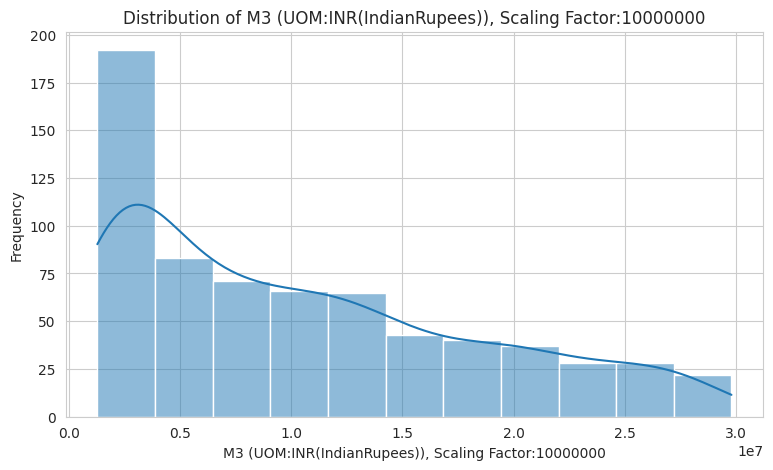

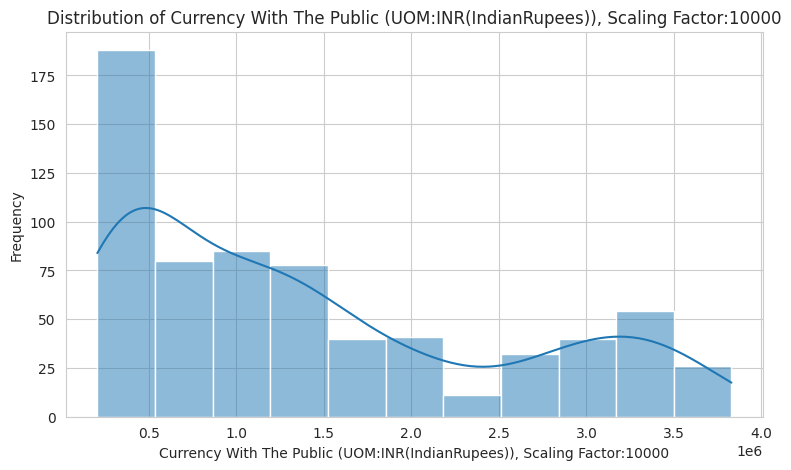

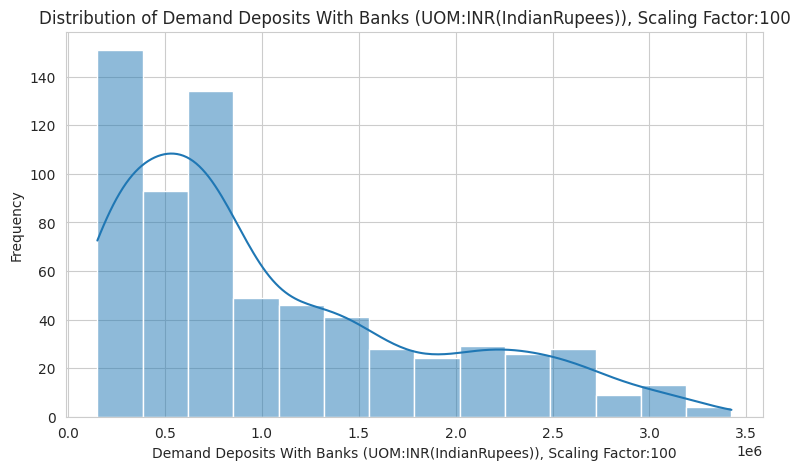

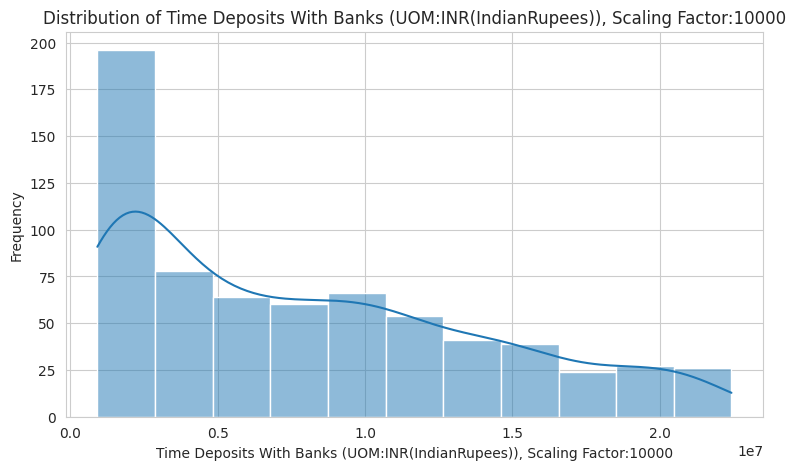

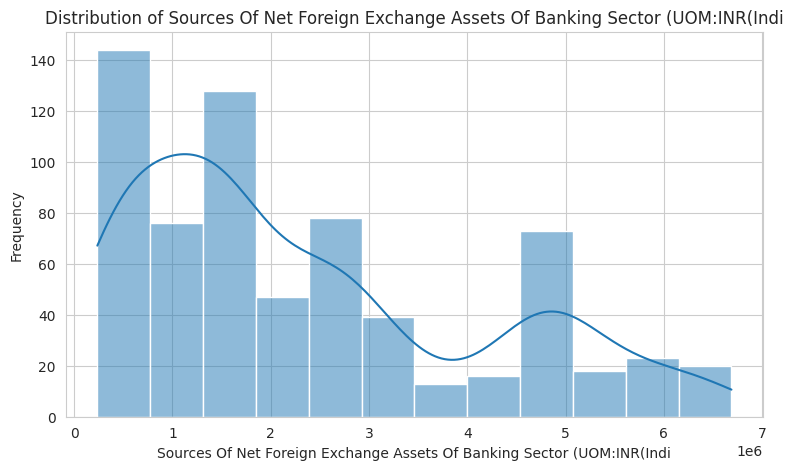

In [18]:
# Select major indicators for readable visual analysis
major_cols = [c for c in [
    m3_col,
    "Currency With The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000",
    "Demand Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000",
    "Time Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000",
    fx_col
] if c in df.columns]

display(
    df[major_cols].describe().T.assign(
        median=df[major_cols].median(),
        skew=df[major_cols].skew(),
        kurtosis=df[major_cols].kurt()
    )
)

for col in major_cols:
    plt.figure()
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"Distribution of {col[:70]}")
    plt.xlabel(col[:70])
    plt.ylabel("Frequency")
    plt.show()


### Step 19 — Bivariate Analysis

**Numerical vs Numerical:** scatter plot + correlation coefficient.

**Numerical vs Time:** line chart to examine movement across observation dates.

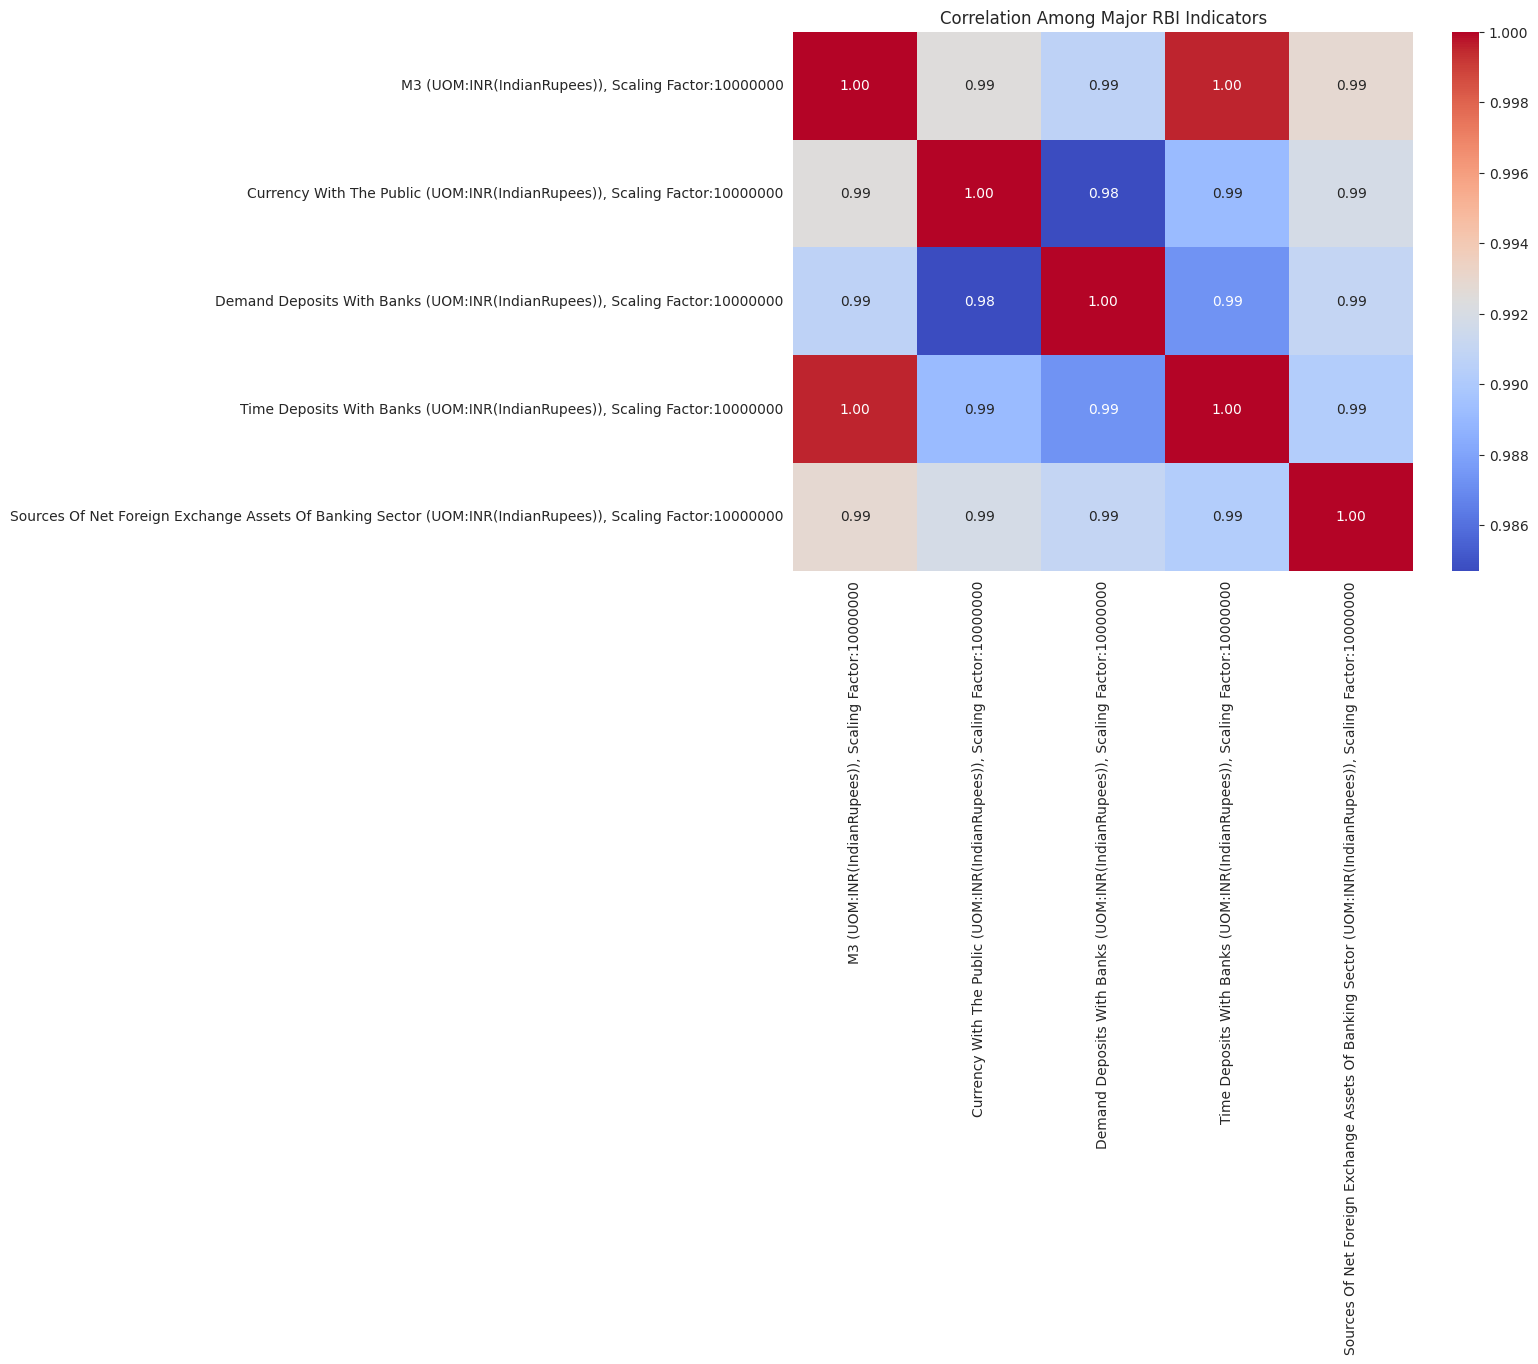

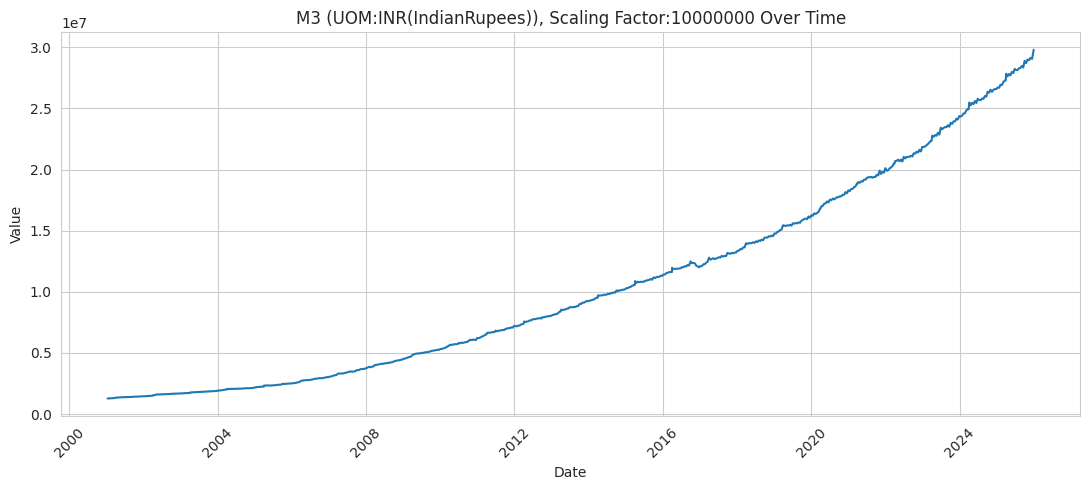

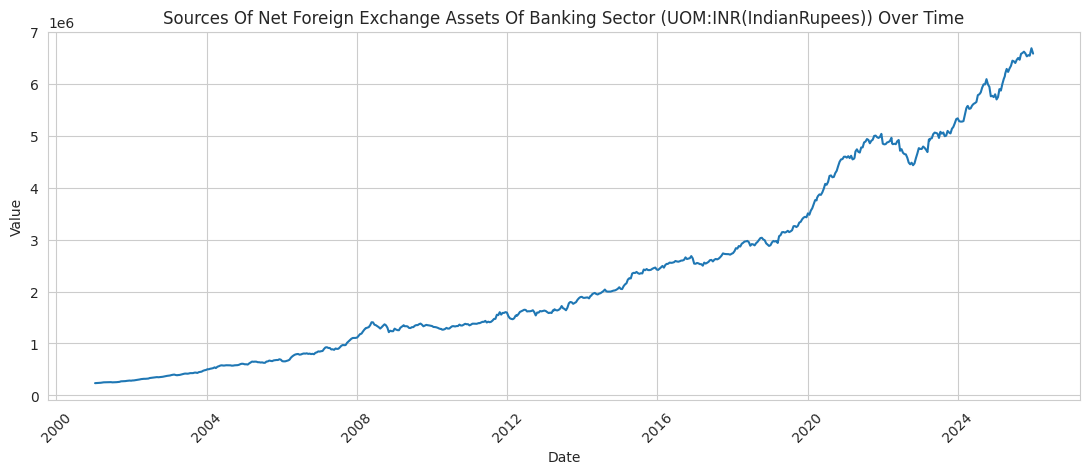

In [19]:
# Correlation among selected major indicators
corr = df[major_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Among Major RBI Indicators")
plt.show()

# M3 and Net Foreign Exchange Assets over time
for col in [m3_col, fx_col]:
    if col:
        plt.figure(figsize=(11, 5))
        plt.plot(df["Date"], df[col])
        plt.title(f"{col[:80]} Over Time")
        plt.xlabel("Date")
        plt.ylabel("Value")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()


### Step 20 — Multivariate Analysis

Use a correlation heatmap, pair plot for selected indicators, and grouped time analysis to understand multiple relationships simultaneously.

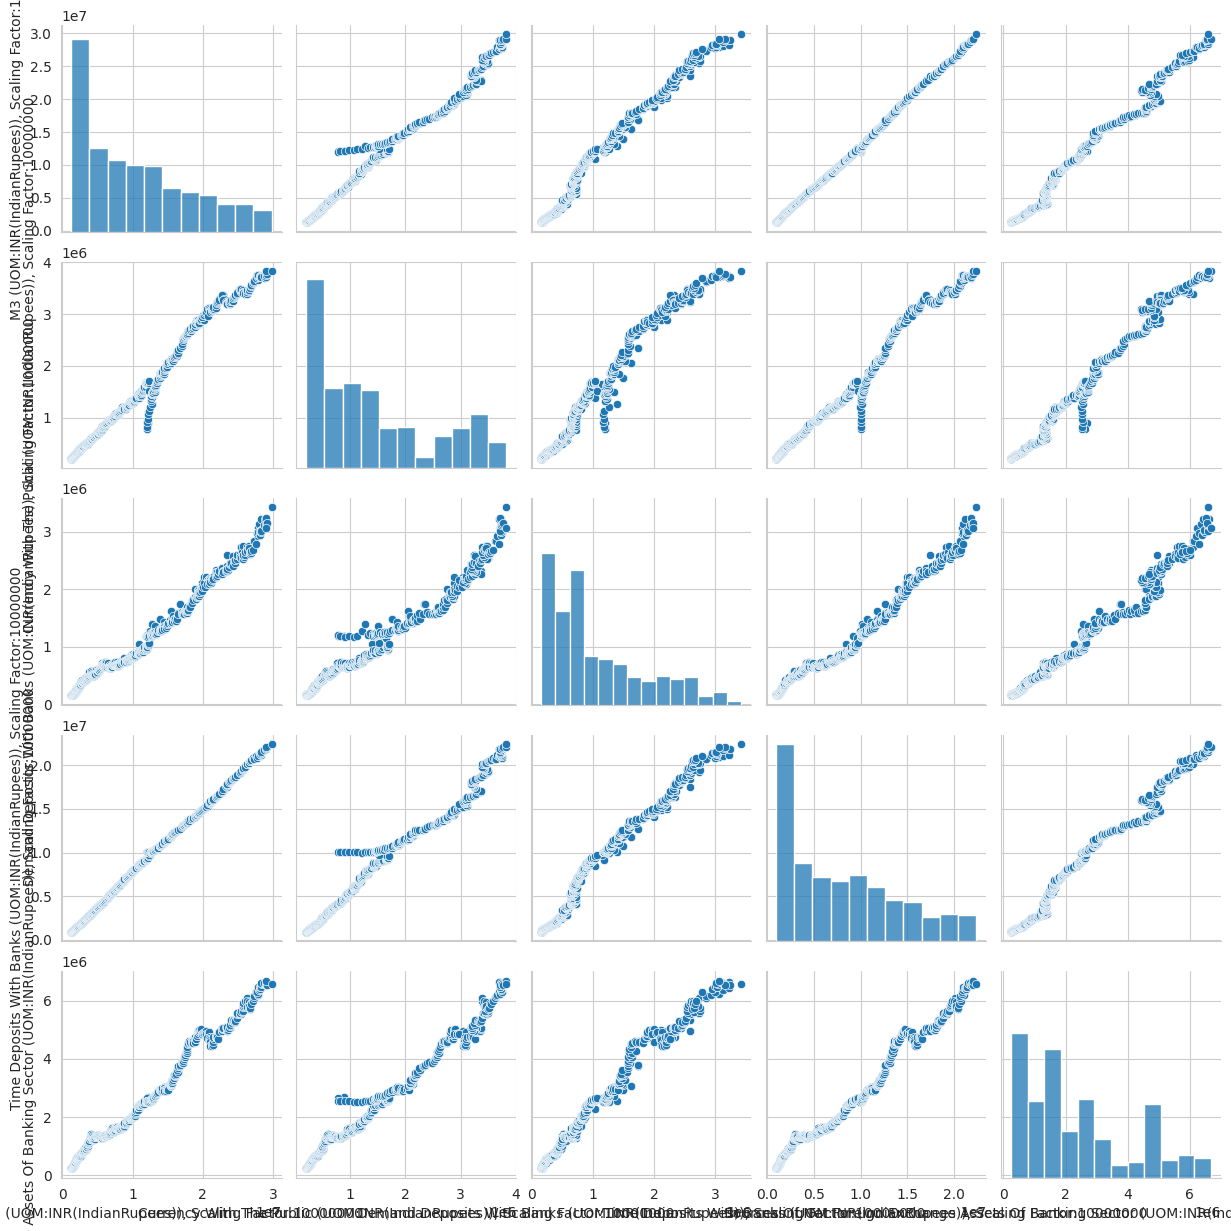

In [20]:
pair_cols = major_cols[:5]

sns.pairplot(
    df[pair_cols].dropna()
)
plt.show()


In [21]:
# Quarterly summary for selected major indicators
quarterly_summary = (
    df.set_index("Date")[major_cols]
      .resample("Q")
      .mean()
)

display(quarterly_summary.tail(10))


/tmp/ipykernel_16/3640762639.py:4: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  .resample("Q")


,"M3 (UOM:INR(IndianRupees)), Scaling Factor:10000000","Currency With The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000","Demand Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000","Time Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000","Sources Of Net Foreign Exchange Assets Of Banking Sector (UOM:INR(IndianRupees)), Scaling Factor:10000000"
Date,,,,,
2023-09-30,2.346501e+07,3.213014e+06,2.345808e+06,1.783385e+07,5.046928e+06
2023-12-31,2.401181e+07,3.232708e+06,2.461055e+06,1.824280e+07,5.189959e+06
2024-03-31,2.466668e+07,3.365671e+06,2.510167e+06,1.870665e+07,5.376033e+06
2024-06-30,2.548707e+07,3.463976e+06,2.630771e+06,1.930288e+07,5.587622e+06
2024-09-30,2.582207e+07,3.420218e+06,2.584696e+06,1.972459e+07,5.889892e+06
2024-12-31,2.646286e+07,3.442028e+06,2.709483e+06,2.021199e+07,5.873363e+06
2025-03-31,2.699733e+07,3.562434e+06,2.704760e+06,2.062075e+07,5.924501e+06
2025-06-30,2.787464e+07,3.715152e+06,3.014883e+06,2.103796e+07,6.322681e+06
2025-09-30,2.828411e+07,3.717574e+06,3.004429e+06,2.145144e+07,6.503223e+06


### Step 21 — Hypothesis Testing

Example research question:

**H₀:** There is no statistically significant linear relationship between M3 and net foreign exchange assets.

**H₁:** There is a statistically significant linear relationship between M3 and net foreign exchange assets.

Pearson correlation is used for the example because both variables are numerical.


In [22]:
if m3_col and fx_col:
    test_df = df[[m3_col, fx_col]].dropna()

    r, p_value = stats.pearsonr(
        test_df[m3_col],
        test_df[fx_col]
    )

    print(f"Pearson correlation (r): {r:.4f}")
    print(f"p-value: {p_value:.6f}")

    alpha = 0.05

    if p_value < alpha:
        print("Decision: Reject H0 at the 5% significance level.")
    else:
        print("Decision: Fail to reject H0 at the 5% significance level.")


Pearson correlation (r): 0.9929
p-value: 0.000000
Decision: Reject H0 at the 5% significance level.


## Phase 4 — Report (Steps 22–23)

Define KPIs and charts for a final RBI economic dashboard.

### Step 22 — Identify Key Metrics / KPIs for Dashboard

Recommended KPIs based on the dataset and problem statement:

- **Latest M3**
- **Latest Net Foreign Exchange Assets**
- **Latest Currency With the Public**
- **Latest Demand Deposits**
- **Latest Time Deposits**
- **Latest Net Bank Credit to Government**
- **Latest Bank Credit to Commercial Sector**
- **M3 Period-over-Period Growth (%)**
- **Net Foreign Exchange Assets Period-over-Period Growth (%)**
- **Observation Date / Latest Reporting Period**


In [23]:
latest = df.sort_values("Date").iloc[-1]

kpis = {}

for label, col in [
    ("Latest M3", m3_col),
    ("Latest Net Foreign Exchange Assets", fx_col),
    ("Latest Currency With Public",
     "Currency With The Public (UOM:INR(IndianRupees)), Scaling Factor:10000000"),
    ("Latest Demand Deposits",
     "Demand Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000"),
    ("Latest Time Deposits",
     "Time Deposits With Banks (UOM:INR(IndianRupees)), Scaling Factor:10000000"),
]:
    if col in df.columns:
        kpis[label] = latest[col]

kpis["Latest Observation Date"] = latest["Date"]

pd.Series(kpis, name="Value")


Latest M3                                     29800906.25
Latest Net Foreign Exchange Assets            6585472.386
Latest Currency With Public                   3828358.658
Latest Demand Deposits                        3423133.329
Latest Time Deposits                          22434415.68
Latest Observation Date               2025-12-31 00:00:00
Name: Value, dtype: object

### Step 23 — Identify Important Charts for Dashboard

Recommended charts:

- **KPI cards** — latest values and latest observation date
- **Line chart** — M3 trend over time
- **Line chart** — Net Foreign Exchange Assets trend over time
- **Multi-line chart** — Currency With Public, Demand Deposits and Time Deposits
- **Line chart** — Net Bank Credit to Government
- **Line chart** — Bank Credit to Commercial Sector
- **Correlation heatmap** — relationships among major indicators
- **Quarterly trend chart** — average indicators by quarter
- **Growth-rate chart** — percentage change in M3 and foreign-exchange assets
- **Data-quality card** — missing values, duplicates and invalid dates after cleaning


In [24]:
# Final dashboard-ready quality summary

quality_summary = pd.Series({
    "Rows": len(df),
    "Columns": len(df.columns),
    "Duplicate Rows": df.duplicated().sum(),
    "Missing Values": df.isnull().sum().sum(),
    "Invalid Dates": df["Date"].isna().sum(),
    "Infinite Values": np.isinf(
        df.select_dtypes(include=np.number)
    ).sum().sum()
})

quality_summary


Rows               675
Columns             34
Duplicate Rows       0
Missing Values       2
Invalid Dates        0
Infinite Values      0
dtype: int64

## Conclusion

All 23 steps of the checklist have been applied end-to-end:

- **Steps 1–8:** the raw RBI dataset was inspected for size, structure, data types, memory usage, duplicates and missing values.
- **Steps 9–17:** variables were classified, dates and numeric fields were cleaned, missing numerical observations were interpolated for the time-series structure, derived time variables were added, outliers were identified without automatic deletion, and the cleaned dataset was exported.
- **Steps 18–21:** univariate, bivariate, multivariate and hypothesis-testing analyses were prepared.
- **Steps 22–23:** dashboard KPIs and recommended visualizations were defined.

**Final output:** `RBI_weekly_dataset_cleaned.csv`
